In [3]:
!pip -q install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 40.8 MB/s eta 0:00:00


In [4]:
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime
from rapidfuzz import process, fuzz

In [6]:
DATA_PATH = "../data/zameen_raw.csv"

df = pd.read_csv(DATA_PATH)

def to_snake(s: str) -> str:
    s = s.strip().replace("/", " ").replace("-", " ")
    s = re.sub(r"[^A-Za-z0-9\s]", "", s)
    s = re.sub(r"\s+", "_", s)
    return s.lower()

df.columns = [to_snake(c) for c in df.columns]

print("Columns:", df.columns.tolist())

Columns: ['title', 'url', 'city', 'type', 'area', 'price', 'purpose', 'location', 'description', 'built_in_year', 'parking_spaces', 'double_glazed_windows', 'central_air_conditioning', 'central_heating', 'flooring', 'electricity_backup', 'waste_disposal', 'floors', 'other_main_features', 'furnished', 'bedrooms', 'bathrooms', 'servant_quarters', 'drawing_room', 'dining_room', 'kitchens', 'study_room', 'prayer_room', 'powder_room', 'store_rooms', 'steam_room', 'lounge_or_sitting_room', 'laundry_room', 'other_rooms', 'broadband_internet_access', 'satellite_or_cable_tv_ready', 'intercom', 'community_lawn_or_garden', 'community_swimming_pool', 'community_gym', 'first_aid_or_medical_centre', 'day_care_centre', 'kids_play_area', 'barbeque_area', 'mosque', 'community_centre', 'lawn_or_garden', 'sauna', 'jacuzzi', 'nearby_schools', 'nearby_hospitals', 'nearby_shopping_malls', 'nearby_restaurants', 'distance_from_airport_kms', 'nearby_public_transport_service', 'other_nearby_places', 'maintenanc

In [7]:
df.head()

,title,url,city,type,area,price,purpose,location,description,built_in_year,parking_spaces,double_glazed_windows,central_air_conditioning,central_heating,flooring,electricity_backup,waste_disposal,floors,other_main_features,furnished,bedrooms,bathrooms,servant_quarters,drawing_room,dining_room,kitchens,study_room,prayer_room,powder_room,store_rooms,steam_room,lounge_or_sitting_room,laundry_room,other_rooms,broadband_internet_access,satellite_or_cable_tv_ready,intercom,community_lawn_or_garden,community_swimming_pool,community_gym,first_aid_or_medical_centre,day_care_centre,kids_play_area,barbeque_area,mosque,community_centre,lawn_or_garden,sauna,jacuzzi,nearby_schools,nearby_hospitals,nearby_shopping_malls,nearby_restaurants,distance_from_airport_kms,nearby_public_transport_service,other_nearby_places,maintenance_staff,security_staff,other_facilities
0,Hmr Waterfront 2 Bed Room Premium Apartment On...,https://www.zameen.com/Property/dha_phase_8_hm...,Karachi,Flat,128 Sq. Yd.,PKR\n4.75 Crore,For Sale,"DHA Defence, Karachi, Sindh",SAIMA MARINA RESIDENCE HMR WATERFRONT\nINVESTO...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Chance Deal! Luxury 2 Bedroom Seafront Apartme...,https://www.zameen.com/Property/dha_defence_dh...,Karachi,Flat,161 Sq. Yd.,PKR\n6.25 Crore,For Sale,"DHA Defence, Karachi, Sindh",Live the Seafront Dream at H&S Residence \n2 B...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,3,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Luxury 1 Bed At H& S Residence By Japanese Arc...,https://www.zameen.com/Property/dha_phase_8_hm...,Karachi,Flat,111 Sq. Yd.,PKR\n3.45 Crore,For Sale,"DHA Defence, Karachi, Sindh",Live the Seafront Dream at H&S Residence \n1 B...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Luxury 1 Bed Seafront Apartment at HMR waterfr...,https://www.zameen.com/Property/dha_phase_8_hm...,Karachi,Flat,106 Sq. Yd.,PKR\n2.98 Crore,For Sale,"DHA Defence, Karachi, Sindh",Chance Deal at HMR Waterfront 1-Bed Apartment ...,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2,1.0,NaN,NaN,4.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2 Bed Apartment For Booking On 3 Years | Saima...,https://www.zameen.com/Property/dha_phase_8_hm...,Karachi,Flat,156 Sq. Yd.,PKR\n4.65 Crore,For Sale,"DHA Defence, Karachi, Sindh",HMR WATERFRONT \n\nOwn Your Dream Apartment in...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.sample(10, random_state=42)

,title,url,city,type,area,price,purpose,location,description,built_in_year,parking_spaces,double_glazed_windows,central_air_conditioning,central_heating,flooring,electricity_backup,waste_disposal,floors,other_main_features,furnished,bedrooms,bathrooms,servant_quarters,drawing_room,dining_room,kitchens,study_room,prayer_room,powder_room,store_rooms,steam_room,lounge_or_sitting_room,laundry_room,other_rooms,broadband_internet_access,satellite_or_cable_tv_ready,intercom,community_lawn_or_garden,community_swimming_pool,community_gym,first_aid_or_medical_centre,day_care_centre,kids_play_area,barbeque_area,mosque,community_centre,lawn_or_garden,sauna,jacuzzi,nearby_schools,nearby_hospitals,nearby_shopping_malls,nearby_restaurants,distance_from_airport_kms,nearby_public_transport_service,other_nearby_places,maintenance_staff,security_staff,other_facilities
8606,5 Marla Beautiful House Urgent For Sale in Can...,https://www.zameen.com/Property/canal_garden_c...,Lahore,House,5 Marla,PKR\n1.88 Crore,For Sale,"Canal Garden, Lahore, Punjab",NaN,2025.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,5,1.0,NaN,NaN,2.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2608,7 Marla Brand New House Available For Sale At ...,https://www.zameen.com/Property/faisalabad_ede...,Faisalabad,House,7 Marla,PKR\n4.25 Crore,For Sale,"Eden Valley, Faisalabad, Punjab",7 Marla brand new double storey house availabl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14586,Fully Furnished 12 Marla House Available In Ba...,https://www.zameen.com/Property/bahria_town_ra...,Rawalpindi,House,12 Marla,PKR\n2.3 Lakh,For,"Bahria Town Rawalpindi, Rawalpindi, Punjab",House is avilable for in bahria town phase 2 ...,2019.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,3,4,1.0,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4254,10 Marla Luxrious House For Sale In New Shalim...,https://www.zameen.com/Property/multan_new_sha...,Multan,House,10 Marla,PKR\n2.5 Crore,For Sale,"New Shalimar Colony, Multan, Punjab",NaN,2024.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,5,6,1.0,NaN,NaN,2.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6926,Get In Touch Now To Buy A Prime Location 5 Mar...,https://www.zameen.com/Property/peshawar_unive...,Peshawar,House,5 Marla,PKR\n2.2 Crore,For Sale,"University Town, Peshawar, Khyber Pakhtunkhwa","Good Location House Available For Sale,\n4 Roo...",2023.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,4,4,2.0,NaN,NaN,2.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16960,10 MARLA 3 BEDROOM APARTMENT AVAILABLE FOR,https://www.zameen.com/Property/askari_10_aska...,Lahore,Flat,10 Marla,PKR\n1.15 Lakh,For,"Askari, Lahore, Punjab",3 BEDROOM ATTACHED BATH\nKITCHEN \nLOUNGE \nPA...,2018.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,4,1.0,NaN,NaN,2.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10540,5MARLA 3 STORY NEW HOME IN G MAGNOLIA BLOCK C ...,https://www.zameen.com/Property/gujranwala_g_m...,Gujranwala,House,5 Marla,PKR\n1.4 Crore,For Sale,"G Magnolia Park, Gujranwala, Punjab",5 MARLA 3 STORY NEW HOME IN BLOCK C AVAILABLE ...,2023.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,5,0.0,NaN,NaN,1.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14433,10 Marla Upper Portion Available For In Media...,https://www.zameen.com/Property/media_town_med...,Rawalpindi,Upper Portion,10 Marla,PKR\n75 Thousand,For,"Media Town, Rawa

In [9]:
df.shape

(18255, 59)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18255 entries, 0 to 18254
Data columns (total 59 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   title                            18239 non-null  object 
 1   url                              18255 non-null  object 
 2   city                             18255 non-null  object 
 3   type                             18239 non-null  object 
 4   area                             18239 non-null  object 
 5   price                            18239 non-null  object 
 6   purpose                          18239 non-null  object 
 7   location                         18239 non-null  object 
 8   description                      14893 non-null  object 
 9   built_in_year                    11940 non-null  float64
 10  parking_spaces                   9656 non-null   float64
 11  double_glazed_windows            0 non-null      float64
 12  central_air_condit

In [11]:
df.describe()

,built_in_year,parking_spaces,double_glazed_windows,central_air_conditioning,central_heating,flooring,electricity_backup,waste_disposal,floors,other_main_features,furnished,servant_quarters,drawing_room,dining_room,kitchens,study_room,prayer_room,powder_room,store_rooms,steam_room,lounge_or_sitting_room,laundry_room,other_rooms,broadband_internet_access,satellite_or_cable_tv_ready,intercom,community_lawn_or_garden,community_swimming_pool,community_gym,first_aid_or_medical_centre,day_care_centre,kids_play_area,barbeque_area,mosque,community_centre,lawn_or_garden,sauna,jacuzzi,nearby_schools,nearby_hospitals,nearby_shopping_malls,nearby_restaurants,distance_from_airport_kms,nearby_public_transport_service,other_nearby_places,maintenance_staff,security_staff,other_facilities
count,11940.000000,9656.000000,0.0,0.0,0.0,0.0,0.0,0.0,8366.000000,0.0,0.0,9657.000000,0.0,0.0,13256.000000,0.0,0.0,0.0,9719.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,1967.123744,5.251833,NaN,NaN,NaN,NaN,NaN,NaN,2.393677,NaN,NaN,1.236823,NaN,NaN,1.686859,NaN,NaN,NaN,1.169565,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1949.941225,41.917894,NaN,NaN,NaN,NaN,NaN,NaN,22.849369,NaN,NaN,0.706476,NaN,NaN,2.022453,NaN,NaN,NaN,0.495977,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2020.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,1.000000,NaN,NaN,1.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2024.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,1.000000,NaN,NaN,2.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2025.000000,3.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,1.000000,NaN,NaN,2.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,202122.000000,2015.000000,NaN,NaN,NaN,NaN,NaN,NaN,2018.000000,NaN,NaN,22.000000,NaN,NaN,211.000000,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df.describe(include="all")

,title,url,city,type,area,price,purpose,location,description,built_in_year,parking_spaces,double_glazed_windows,central_air_conditioning,central_heating,flooring,electricity_backup,waste_disposal,floors,other_main_features,furnished,bedrooms,bathrooms,servant_quarters,drawing_room,dining_room,kitchens,study_room,prayer_room,powder_room,store_rooms,steam_room,lounge_or_sitting_room,laundry_room,other_rooms,broadband_internet_access,satellite_or_cable_tv_ready,intercom,community_lawn_or_garden,community_swimming_pool,community_gym,first_aid_or_medical_centre,day_care_centre,kids_play_area,barbeque_area,mosque,community_centre,lawn_or_garden,sauna,jacuzzi,nearby_schools,nearby_hospitals,nearby_shopping_malls,nearby_restaurants,distance_from_airport_kms,nearby_public_transport_service,other_nearby_places,maintenance_staff,security_staff,other_facilities
count,18239,18255,18255,18239,18239,18239,18239,18239,14893,11940.000000,9656.000000,0.0,0.0,0.0,0.0,0.0,0.0,8366.000000,0.0,0.0,18239,18239,9657.000000,0.0,0.0,13256.000000,0.0,0.0,0.0,9719.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
unique,16064,18255,84,7,468,1022,2,1051,13617,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,House For Sale,https://www.zameen.com/Property/dera_ghazi_kha...,Karachi,House,5 Marla,PKR\n60 Thousand,For Sale,"Bahria Town Rawalpindi, Rawalpindi, Punjab",Marriott Estate And Builders Offer a Ideal Hou...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,43,1,1250,13386,3528,269,11126,1884,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4174,4993,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1967.123744,5.251833,NaN,NaN,NaN,NaN,NaN,NaN,2.393677,NaN,NaN,NaN,NaN,1.236823,NaN,NaN,1.686859,NaN,NaN,NaN,1.169565,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1949.941225,41.917894,NaN,NaN,NaN,NaN,NaN,NaN,22.849369,NaN,NaN,NaN,NaN,0.706476,NaN,NaN,2.022453,NaN,NaN,NaN,0.495977,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,1.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,2.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025.000000,3.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,2.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df.columns.tolist()

['title',
 'url',
 'city',
 'type',
 'area',
 'price',
 'purpose',
 'location',
 'description',
 'built_in_year',
 'parking_spaces',
 'double_glazed_windows',
 'central_air_conditioning',
 'central_heating',
 'flooring',
 'electricity_backup',
 'waste_disposal',
 'floors',
 'other_main_features',
 'furnished',
 'bedrooms',
 'bathrooms',
 'servant_quarters',
 'drawing_room',
 'dining_room',
 'kitchens',
 'study_room',
 'prayer_room',
 'powder_room',
 'store_rooms',
 'steam_room',
 'lounge_or_sitting_room',
 'laundry_room',
 'other_rooms',
 'broadband_internet_access',
 'satellite_or_cable_tv_ready',
 'intercom',
 'community_lawn_or_garden',
 'community_swimming_pool',
 'community_gym',
 'first_aid_or_medical_centre',
 'day_care_centre',
 'kids_play_area',
 'barbeque_area',
 'mosque',
 'community_centre',
 'lawn_or_garden',
 'sauna',
 'jacuzzi',
 'nearby_schools',
 'nearby_hospitals',
 'nearby_shopping_malls',
 'nearby_restaurants',
 'distance_from_airport_kms',
 'nearby_public_transport

In [14]:
df.dtypes

,0
title,object
url,object
city,object
type,object
area,object
price,object
purpose,object
location,object
description,object
built_in_year,float64


In [15]:
possible_cols = {
    "title": ["title","listing_title"],
    "city": ["city","location_city","city_name"],
    "area_name": ["area","area_name","neighborhood","locality"],
    "price_raw": ["price","price_pkr","asking_price"],
    "property_type": ["property_type","type","category"],
    "area_raw": ["area_size","area","size","plot_area"],
    "beds": ["beds","bedrooms","no_of_beds"],
    "baths": ["baths","bathrooms","no_of_baths"],
    "date_posted": ["date_posted","posted_on","posting_date","date"],
    "description": ["description","details","desc","remarks"]
}

def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

cols = {k: pick_col(df, v) for k, v in possible_cols.items()}
cols


{'title': 'title',
 'city': 'city',
 'area_name': 'area',
 'price_raw': 'price',
 'property_type': 'type',
 'area_raw': 'area',
 'beds': 'bedrooms',
 'baths': 'bathrooms',
 'date_posted': None,
 'description': 'description'}

In [16]:
def parse_price_to_pkr(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    s = s.replace("pkr", "").replace(",", " ").replace(" ", "")
    m = re.match(r"([\d\.]+)(crore|cr)", s)
    if m:
        return float(m.group(1)) * 10000000.0
    m = re.match(r"([\d\.]+)(lakh|lac|lk)", s)
    if m:
        return float(m.group(1)) * 100000.0
    m = re.findall(r"[\d\.]+", s)
    if m:
        try:
            return float("".join(m))
        except:
            return np.nan
    return np.nan

In [17]:
price_col = cols["price_raw"]
if price_col:
    df["price_pkr"] = df[price_col].apply(parse_price_to_pkr)
else:
    numeric_like = [c for c in df.columns if "price" in c and df[c].notna().sum() > 0]
    if numeric_like:
        df["price_pkr"] = pd.to_numeric(df[numeric_like[0]], errors="coerce")
    else:
        df["price_pkr"] = np.nan

In [18]:
df[["price_pkr"]].head()

,price_pkr
0,4.75
1,6.25
2,3.45
3,2.98
4,4.65


In [19]:
UNIT_FACTORS = {
    "marla": 272.25,
    "kanal": 272.25 * 20,
    "sqft": 1.0,
    "squarefeet": 1.0,
    "sq_ft": 1.0,
    "sqyd": 9.0,
    "squareyards": 9.0,
    "sq_yard": 9.0,
    "sqyds": 9.0,
    "sqy": 9.0,
    "sqm": 10.7639,
    "squaremeters": 10.7639,
    "acre": 43560.0,
    "acres": 43560.0
}

In [20]:

def detect_unit(s: str):
    s = s.lower().replace(".", "").replace(" ", "")
    for u in UNIT_FACTORS:
        if u in s:
            return u
    return "sqft"

In [21]:
def parse_area_to_sqft(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    nums = re.findall(r"[\d\.]+", s)
    if not nums:
        return np.nan
    val = float(nums[0])
    unit = detect_unit(s)
    factor = UNIT_FACTORS.get(unit, 1.0)
    return val * factor

In [22]:
area_col = cols["area_raw"]
if area_col:
    df["area_sqft"] = df[area_col].apply(parse_area_to_sqft)
else:
    guessed = [c for c in df.columns if "area" in c or "size" in c]
    if guessed:
        df["area_sqft"] = df[guessed[0]].apply(parse_area_to_sqft)
    else:
        df["area_sqft"] = np.nan

In [23]:
df[["area_sqft"]].head()

,area_sqft
0,1152.0
1,1449.0
2,999.0
3,954.0
4,1404.0


In [24]:
date_col = cols["date_posted"]
if date_col:
    df["date_posted"] = pd.to_datetime(df[date_col], errors="coerce")
    df["posting_year"] = df["date_posted"].dt.year
    df["posting_month"] = df["date_posted"].dt.month
else:
    df["date_posted"] = pd.NaT
    df["posting_year"] = np.nan
    df["posting_month"] = np.nan

In [25]:
for k in ["beds","baths"]:
    c = cols.get(k)
    if c:
        df[k] = pd.to_numeric(df[c], errors="coerce")

In [26]:
for alias, new_col in [("city","city"), ("area_name","area_name"), ("property_type","property_type"), ("title","title"), ("description","description")]:
    src = cols.get(alias)
    if src and src != new_col:
        df[new_col] = df[src]
    elif src is None and new_col not in df:
        df[new_col] = np.nan

In [27]:
df[["price_pkr","area_sqft","beds","baths","city","area_name","property_type","date_posted"]].head(10)

,price_pkr,area_sqft,beds,baths,city,area_name,property_type,date_posted
0,4.75,1152.0,2.0,2.0,Karachi,128 Sq. Yd.,Flat,NaT
1,6.25,1449.0,2.0,3.0,Karachi,161 Sq. Yd.,Flat,NaT
2,3.45,999.0,1.0,2.0,Karachi,111 Sq. Yd.,Flat,NaT
3,2.98,954.0,1.0,2.0,Karachi,106 Sq. Yd.,Flat,NaT
4,4.65,1404.0,2.0,2.0,Karachi,156 Sq. Yd.,Flat,NaT
5,2.60,1953.0,3.0,3.0,Karachi,217 Sq. Yd.,Flat,NaT
6,6.75,2160.0,9.0,6.0,Karachi,240 Sq. Yd.,House,NaT
7,1.68,1800.0,3.0,3.0,Karachi,200 Sq. Yd.,House,NaT
8,8.00,2700.0,6.0,6.0,Karachi,300 Sq. Yd.,House,NaT
9,4.40,1701.0,3.0,3.0,Karachi,189 Sq. Yd.,Flat,NaT


In [28]:
dupe_count = df.duplicated().sum()
print("Duplicate rows found:", dupe_count)
df = df.drop_duplicates()

Duplicate rows found: 0


In [29]:
print("\nMissing values BEFORE:")
display(df.isna().sum().sort_values(ascending=False))


Missing values BEFORE:


,0
waste_disposal,18255
other_main_features,18255
furnished,18255
double_glazed_windows,18255
nearby_restaurants,18255
...,...
location,16
area_name,16
property_type,16
city,0


In [30]:
for col in ["price_pkr", "area_sqft", "beds", "baths"]:
    if col in df.columns:
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)

/tmp/ipython-input-4209002994.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)


In [31]:
for col in ["city", "area_name", "property_type", "title", "description"]:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

In [32]:
print("\nMissing values AFTER:")
display(df.isna().sum().sort_values(ascending=False))


Missing values AFTER:


,0
waste_disposal,18255
other_main_features,18255
furnished,18255
double_glazed_windows,18255
nearby_restaurants,18255
...,...
area_sqft,0
beds,0
baths,0
area_name,0


In [33]:
if "city" in df.columns:
    top_cities = df["city"].value_counts().head(50).index.tolist()
else:
    top_cities = []

In [34]:
def standardize_city(x, choices=top_cities):
    if pd.isna(x) or not isinstance(x, str) or not choices:
        return x
    match, score, _ = process.extractOne(x, choices, scorer=fuzz.WRatio)
    return match if score >= 90 else x

In [35]:
if "city" in df.columns and len(top_cities) > 0:
    df["city_std"] = df["city"].astype(str).apply(standardize_city)
else:
    df["city_std"] = df.get("city", np.nan)

In [36]:
prop_map = {
    "house":"house", "home":"house", "independenthouse":"house",
    "apartment":"apartment", "flat":"apartment",
    "plot":"plot", "residentialplot":"plot", "commercialplot":"plot",
    "upperportion":"portion", "lowerportion":"portion", "portion":"portion",
    "farmhouse":"farmhouse", "villa":"house", "penthouse":"apartment",
    "office":"office", "shop":"shop", "warehouse":"warehouse"
}

In [37]:
def normalize_property_type(x):
    if pd.isna(x): return x
    s = re.sub(r"[^a-z]", "", str(x).lower())
    return prop_map.get(s, x)

In [38]:
df["property_type_std"] = df["property_type"].apply(normalize_property_type)

In [39]:
df[["city","city_std","property_type","property_type_std"]].head(15)

,city,city_std,property_type,property_type_std
0,Karachi,Karachi,Flat,apartment
1,Karachi,Karachi,Flat,apartment
2,Karachi,Karachi,Flat,apartment
3,Karachi,Karachi,Flat,apartment
4,Karachi,Karachi,Flat,apartment
5,Karachi,Karachi,Flat,apartment
6,Karachi,Karachi,House,house
7,Karachi,Karachi,House,house
8,Karachi,Karachi,House,house
9,Karachi,Karachi,Flat,apartment


In [40]:
df["price_per_sqft"] = df.apply(lambda r: r["price_pkr"]/r["area_sqft"] if r["area_sqft"] and r["area_sqft"]>0 else np.nan, axis=1)
df["log_price"] = np.log1p(df["price_pkr"])
df["log_area"] = np.log1p(df["area_sqft"])

In [41]:
df["bedroom_bucket"] = pd.cut(df["beds"], bins=[-np.inf,1,2,3,4,5,np.inf], labels=["≤1","2","3","4","5","6+"])
df["bathroom_bucket"] = pd.cut(df["baths"], bins=[-np.inf,1,2,3,4,5,np.inf], labels=["≤1","2","3","4","5","6+"])

df[["price_pkr","area_sqft","price_per_sqft","log_price","log_area","bedroom_bucket"]].head(10)

,price_pkr,area_sqft,price_per_sqft,log_price,log_area,bedroom_bucket
0,4.75,1152.0,0.004123,1.749200,7.050123,2
1,6.25,1449.0,0.004313,1.981001,7.279319,2
2,3.45,999.0,0.003453,1.492904,6.907755,≤1
3,2.98,954.0,0.003124,1.381282,6.861711,≤1
4,4.65,1404.0,0.003312,1.731656,7.247793,2
5,2.60,1953.0,0.001331,1.280934,7.577634,3
6,6.75,2160.0,0.003125,2.047693,7.678326,6+
7,1.68,1800.0,0.000933,0.985817,7.496097,3
8,8.00,2700.0,0.002963,2.197225,7.901377,6+
9,4.40,1701.0,0.002587,1.686399,7.439559,3


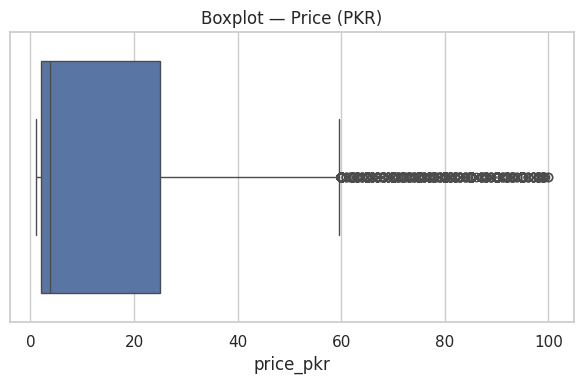

In [42]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["price_pkr"])
plt.title("Boxplot — Price (PKR)")
plt.tight_layout()
plt.show()

In [43]:
Q1 = df["price_pkr"].quantile(0.25)
Q3 = df["price_pkr"].quantile(0.75)
IQR = Q3 - Q1
lb = Q1 - 1.5*IQR
ub = Q3 + 1.5*IQR

In [44]:
print(f"IQR bounds — lower: {lb:,.0f}, upper: {ub:,.0f}")
out_iqr = df[(df["price_pkr"] < lb) | (df["price_pkr"] > ub)]
print("IQR outliers count:", len(out_iqr))
out_iqr[["price_pkr","area_sqft","city_std","property_type_std"]].head(10)

IQR bounds — lower: -33, upper: 60
IQR outliers count: 2499


,price_pkr,area_sqft,city_std,property_type_std
49,60.0,648.0,Karachi,apartment
65,70.0,648.0,Karachi,apartment
70,93.0,999.0,Karachi,apartment
72,68.0,648.0,Karachi,apartment
91,80.0,1404.0,Karachi,apartment
104,85.0,1098.0,Karachi,apartment
107,70.0,864.0,Karachi,apartment
129,98.0,1080.0,Karachi,house
130,81.0,900.0,Karachi,house
154,60.0,954.0,Karachi,apartment


In [45]:
z = (df["price_pkr"] - df["price_pkr"].mean()) / df["price_pkr"].std(ddof=0)
df["z_score_price"] = z
out_z = df[(z > 3) | (z < -3)]
print("Z-score outliers count:", len(out_z))
out_z[["price_pkr","area_sqft","city_std","property_type_std","z_score_price"]].head(10)

Z-score outliers count: 3


,price_pkr,area_sqft,city_std,property_type_std,z_score_price
1553,100.00,1279.575,Islamabad,apartment,3.034628
2325,99.84,762.300,Islamabad,apartment,3.028678
4426,99.36,680.625,Multan,apartment,3.010829


In [46]:
df.drop(columns=["z_score_price"], inplace=True)

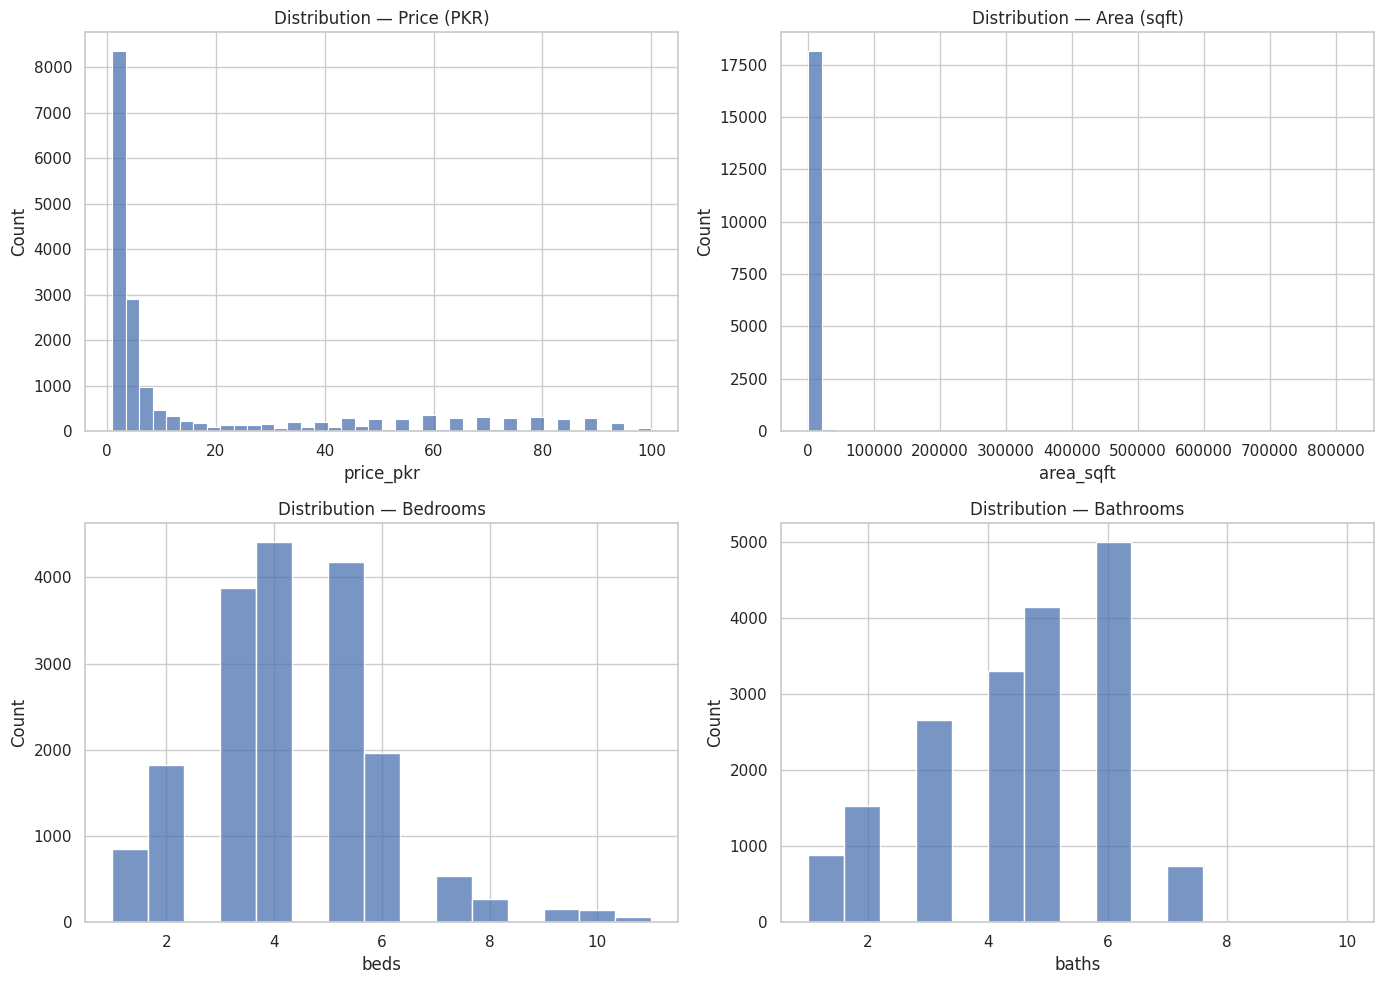

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

sns.histplot(df["price_pkr"], bins=40, ax=axes[0,0])
axes[0,0].set_title("Distribution — Price (PKR)")

sns.histplot(df["area_sqft"], bins=40, ax=axes[0,1])
axes[0,1].set_title("Distribution — Area (sqft)")

sns.histplot(df["beds"], bins=15, ax=axes[1,0])
axes[1,0].set_title("Distribution — Bedrooms")

sns.histplot(df["baths"], bins=15, ax=axes[1,1])
axes[1,1].set_title("Distribution — Bathrooms")

plt.tight_layout()
plt.show()


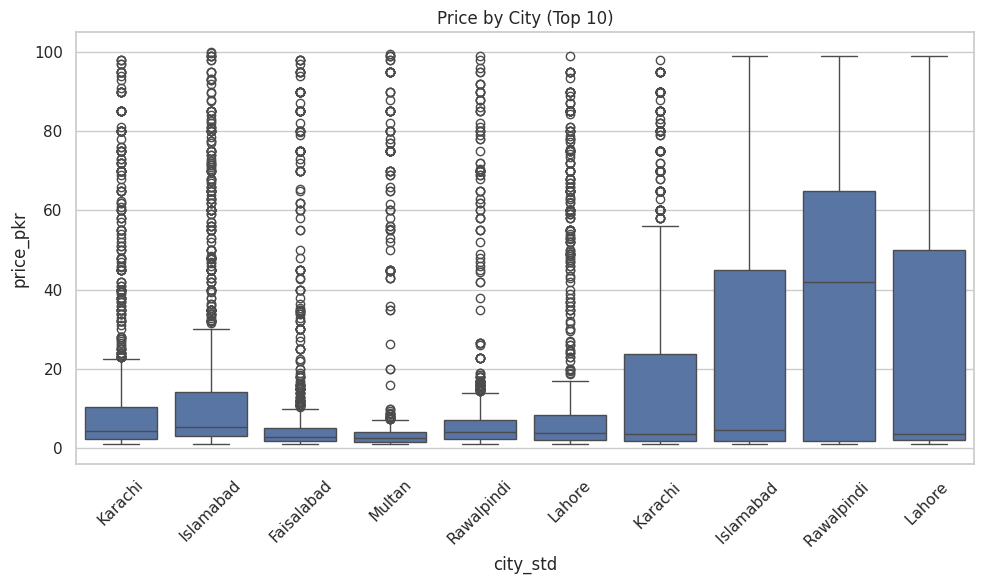

In [48]:
top_cities = df["city_std"].value_counts().head(10).index
plt.figure(figsize=(10,6))
sns.boxplot(data=df[df["city_std"].isin(top_cities)], x="city_std", y="price_pkr")
plt.title("Price by City (Top 10)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

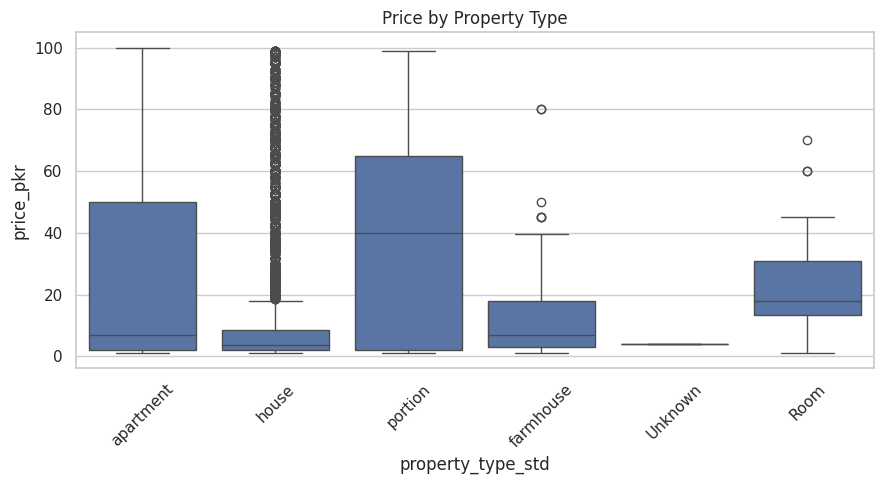

In [49]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x="property_type_std", y="price_pkr")
plt.title("Price by Property Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

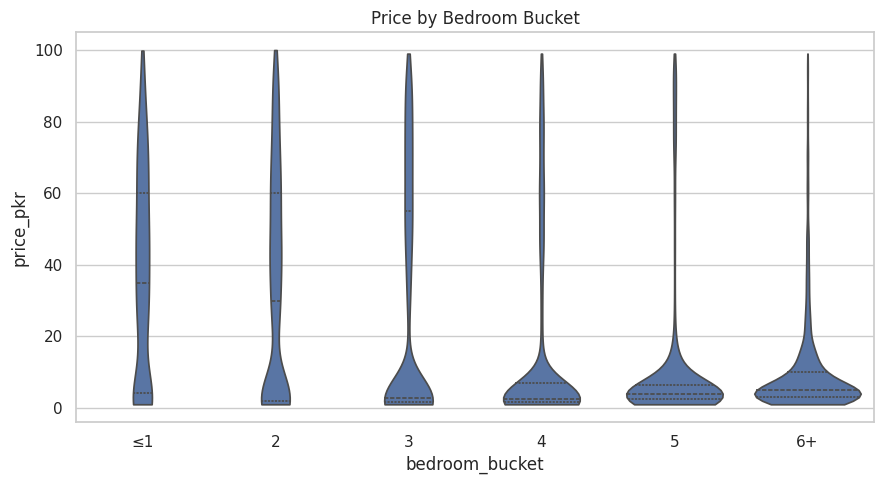

In [50]:
plt.figure(figsize=(9,5))
sns.violinplot(data=df, x="bedroom_bucket", y="price_pkr", inner="quartile", cut=0)
plt.title("Price by Bedroom Bucket")
plt.tight_layout()
plt.show()

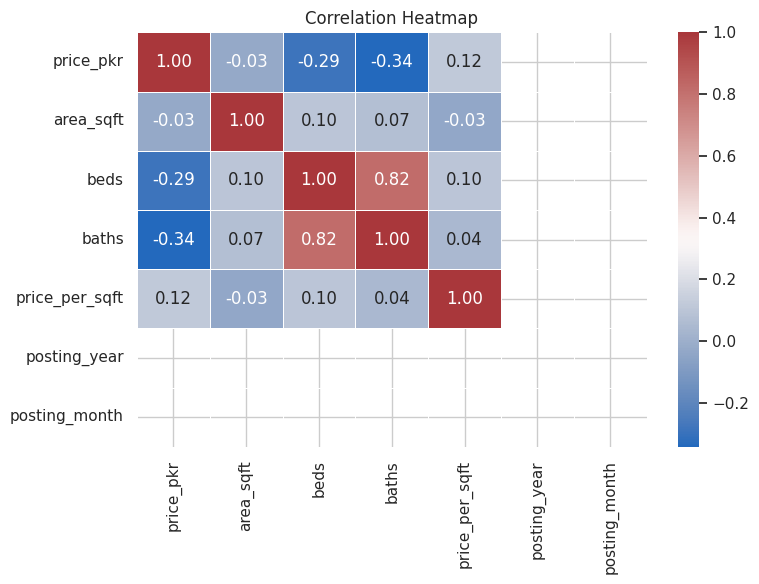

In [51]:
num_cols = ["price_pkr","area_sqft","beds","baths","price_per_sqft","posting_year","posting_month"]
num_cols = [c for c in num_cols if c in df.columns]
corr = df[num_cols].corr(numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", linewidths=.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [52]:
ppsf_by_city = (df[df["city_std"].isin(top_cities)]
                .groupby("city_std")["price_per_sqft"]
                .median()
                .sort_values(ascending=False))
print("Median Price per sqft by City (Top 10):")
ppsf_by_city

Median Price per sqft by City (Top 10):


,price_per_sqft
city_std,
Rawalpindi,0.020202
Karachi,0.002278
Islamabad,0.001974
Lahore,0.001543
Rawalpindi,0.001481
Faisalabad,0.001469
Islamabad,0.001173
Multan,0.001157
Karachi,0.001111


In [53]:
med_price_by_type = df.groupby("property_type_std")["price_pkr"].median().sort_values(ascending=False)
print("\nMedian Price by Property Type:")
med_price_by_type


Median Price by Property Type:


,price_pkr
property_type_std,
portion,40.000
Room,18.000
farmhouse,7.000
apartment,6.775
Unknown,3.850
house,3.500


In [54]:
beds_price = df.groupby("beds")["price_pkr"].median().sort_index()
print("\nMedian Price by Bedrooms:")
beds_price


Median Price by Bedrooms:


,price_pkr
beds,
1.0,35.000
2.0,30.000
3.0,2.750
4.0,2.500
5.0,3.800
6.0,4.450
7.0,5.200
8.0,4.875
9.0,5.000


In [55]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
clean_path = OUTPUT_DIR / "zameen_cleaned.csv"
df.to_csv(clean_path, index=False)
print(f"Cleaned data saved to: {clean_path.resolve()}")

Cleaned data saved to: /content/outputs/zameen_cleaned.csv
